# 04 – DDPM: Huấn luyện và kết quả (TV3 – Phase 2)

Notebook này **tổng hợp kết quả đã huấn luyện**, không tự chạy lại 30 epochs. Hãy chạy lệnh train ở terminal trước, sau đó chạy các cell để đọc cấu hình, log, checkpoint, loss curve và ảnh mẫu.

Lệnh huấn luyện mặc định:

```bash
python main.py train --config configs/ddpm.yaml
```

Lệnh sinh ảnh từ checkpoint:

```bash
python main.py sample --config configs/ddpm.yaml --ckpt checkpoints/ddpm_best.pth --n-samples 16
```

> Các kết quả hiển thị trong notebook được đọc từ file đã lưu trong workspace. Notebook không tự tạo số liệu thay cho lần chạy thực tế.

In [1]:
from pathlib import Path
import os
import json

# Tìm thư mục gốc dự án kể cả khi notebook được mở từ thư mục notebooks/.
search_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in search_roots if (p / "configs" / "ddpm.yaml").is_file()
     and (p / "src" / "models" / "ddpm.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy project root. Hãy mở notebook trong repository có configs/ddpm.yaml "
        "và src/models/ddpm.py."
    )
os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)


Project root: d:\moist\hocsau\baitapnhom\DeepLearning_BTL


In [2]:
import torch
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

from src.utils import load_config

cfg = load_config("configs/ddpm.yaml")
output_cfg = cfg.get("output", {})

def project_path(value):
    path = Path(value)
    return path if path.is_absolute() else PROJECT_ROOT / path

CHECKPOINT_DIR = project_path(output_cfg.get("checkpoint_dir", "checkpoints"))
SAMPLE_BASE_DIR = project_path(output_cfg.get("sample_dir", "outputs/samples"))
LOG_DIR = project_path(output_cfg.get("log_dir", "outputs"))
LOG_PATH = LOG_DIR / "ddpm_train_log.json"
LOSS_CURVE_PATH = LOG_DIR / "ddpm_loss_curve.png"
BEST_CKPT_PATH = CHECKPOINT_DIR / "ddpm_best.pth"
LAST_CKPT_PATH = CHECKPOINT_DIR / "ddpm_last.pth"
SAMPLE_DIR = SAMPLE_BASE_DIR / "ddpm"

print("Dataset:", cfg.get("data", {}).get("name", "chưa khai báo"))
print("Training config:", cfg.get("train", {}))
print("Model config:", cfg.get("model", {}))
print("Log:", LOG_PATH)
print("Best checkpoint:", BEST_CKPT_PATH)


Dataset: fashion_mnist
Training config: {'epochs': 30, 'lr': 0.0002, 'ema_decay': 0.999}
Model config: {'name': 'ddpm', 'timesteps': 1000, 'beta_schedule': 'linear', 'base_channels': 64, 'channel_mults': [1, 2, 2]}
Log: d:\moist\hocsau\baitapnhom\DeepLearning_BTL\outputs\ddpm_train_log.json
Best checkpoint: d:\moist\hocsau\baitapnhom\DeepLearning_BTL\checkpoints\ddpm_best.pth


## 1. Lịch sử huấn luyện

Cell tiếp theo đọc `ddpm_train_log.json`. File này được tạo sau khi training hoàn tất; nếu trainer đã được cập nhật để lưu từng epoch thì notebook cũng có thể đọc tiến độ đang chạy.

In [4]:
if not LOG_PATH.is_file():
    raise FileNotFoundError(
        f"Chưa tìm thấy {LOG_PATH}. Hãy chạy training trước:\n"
        "python main.py train --config configs/ddpm.yaml"
    )

with LOG_PATH.open("r", encoding="utf-8") as f:
    training_log = json.load(f)

history = training_log.get("history", [])
print("Trạng thái log:", training_log.get("status", "không được ghi trong log phiên bản cũ"))
print("Epoch đã ghi nhận:", len(history), "/", training_log.get("epochs", "không rõ"))
print("Best validation loss:", training_log.get("best_val_loss"))
print("Tổng thời gian (giây):", training_log.get("total_time_sec"))


Trạng thái log: completed
Epoch đã ghi nhận: 30 / 30
Best validation loss: 0.02163333806395531
Tổng thời gian (giây): 5050.97


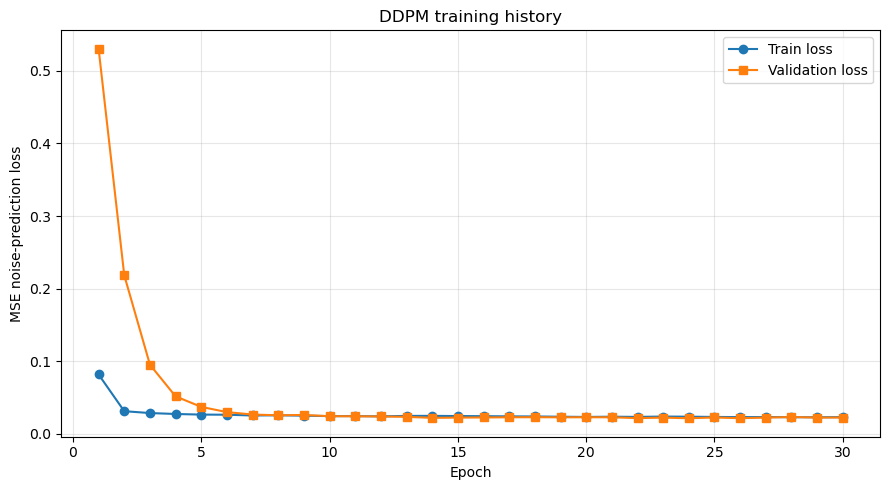

{'epoch': 1, 'train_loss': 0.08187, 'val_loss': 0.53029, 'duration_sec': 185.35}
{'epoch': 2, 'train_loss': 0.03134, 'val_loss': 0.21837, 'duration_sec': 169.0}
{'epoch': 3, 'train_loss': 0.02879, 'val_loss': 0.09536, 'duration_sec': 168.29}
{'epoch': 4, 'train_loss': 0.0275, 'val_loss': 0.05178, 'duration_sec': 166.42}
{'epoch': 5, 'train_loss': 0.02666, 'val_loss': 0.03725, 'duration_sec': 166.34}
{'epoch': 6, 'train_loss': 0.0265, 'val_loss': 0.0301, 'duration_sec': 166.39}
{'epoch': 7, 'train_loss': 0.02543, 'val_loss': 0.02673, 'duration_sec': 166.32}
{'epoch': 8, 'train_loss': 0.02571, 'val_loss': 0.02571, 'duration_sec': 166.34}
{'epoch': 9, 'train_loss': 0.0252, 'val_loss': 0.02616, 'duration_sec': 166.45}
{'epoch': 10, 'train_loss': 0.02455, 'val_loss': 0.02445, 'duration_sec': 166.33}
{'epoch': 11, 'train_loss': 0.02458, 'val_loss': 0.02435, 'duration_sec': 166.4}
{'epoch': 12, 'train_loss': 0.02426, 'val_loss': 0.02407, 'duration_sec': 166.31}
{'epoch': 13, 'train_loss': 0.0

In [5]:
if history:
    epochs = [row["epoch"] for row in history]
    train_losses = [row["train_loss"] for row in history]
    val_losses = [row["val_loss"] for row in history]

    plt.figure(figsize=(9, 5))
    plt.plot(epochs, train_losses, marker="o", label="Train loss")
    plt.plot(epochs, val_losses, marker="s", label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE noise-prediction loss")
    plt.title("DDPM training history")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Log chưa có history; chưa thể vẽ loss curve.")

# Hiển thị chi tiết từng epoch đã được ghi vào JSON.
for row in history:
    print(row)


## 2. Thông tin checkpoint

Checkpoint tốt nhất lưu model weights, optimizer state, EMA state, cấu hình kiến trúc, cấu hình training và epoch tương ứng.

In [6]:
if not BEST_CKPT_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy checkpoint: {BEST_CKPT_PATH}")

# Checkpoint do chính dự án tạo ra. weights_only=False cần thiết với một số phiên bản
# PyTorch khi payload chứa thêm metadata Python ngoài tensor.
try:
    checkpoint = torch.load(BEST_CKPT_PATH, map_location="cpu", weights_only=False)
except TypeError:  # Tương thích phiên bản PyTorch cũ chưa có tham số weights_only.
    checkpoint = torch.load(BEST_CKPT_PATH, map_location="cpu")

checkpoint_summary = {
    "epoch": checkpoint.get("epoch"),
    "train_loss": checkpoint.get("train_loss"),
    "val_loss": checkpoint.get("val_loss"),
    "best_val_loss": checkpoint.get("best_val_loss"),
    "seed": checkpoint.get("seed"),
    "has_ema": checkpoint.get("ema_state_dict") is not None,
}
print("Checkpoint summary:")
for key, value in checkpoint_summary.items():
    print(f"- {key}: {value}")

print("\nModel config:")
print(json.dumps(checkpoint.get("model_config", {}), indent=2, ensure_ascii=False))
print("\nTrain config:")
print(json.dumps(checkpoint.get("train_config", {}), indent=2, ensure_ascii=False))


Checkpoint summary:
- epoch: 24
- train_loss: 0.02375820466934431
- val_loss: 0.02163333806395531
- best_val_loss: 0.02163333806395531
- seed: 42
- has_ema: True

Model config:
{
  "channels": 1,
  "image_size": 32,
  "num_classes": 10,
  "timesteps": 1000,
  "beta_start": 0.0001,
  "beta_end": 0.02,
  "beta_schedule": "linear",
  "base_channels": 64,
  "channel_mults": [
    1,
    2,
    2
  ],
  "num_res_blocks": 2,
  "dropout": 0.0
}

Train config:
{
  "epochs": 30,
  "lr": 0.0002,
  "ema_decay": 0.999,
  "sample_every": 30,
  "n_preview": 16
}


## 3. Loss curve đã lưu từ training script

Đây là ảnh biểu đồ được `train_ddpm.py` lưu ra thư mục output. Nếu chưa có, kiểm tra log training và phiên bản trainer đang dùng.

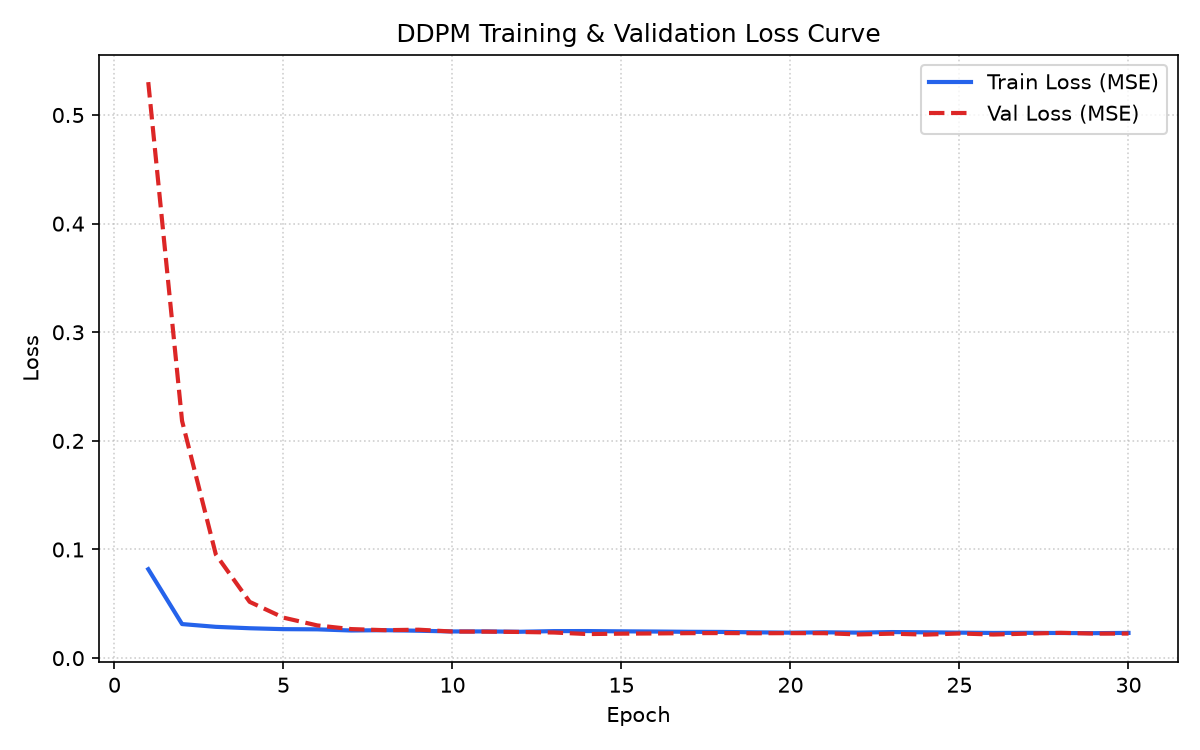

In [7]:
if LOSS_CURVE_PATH.is_file():
    display(Image(filename=str(LOSS_CURVE_PATH)))
else:
    print(f"Chưa có file biểu đồ: {LOSS_CURVE_PATH}")
    print("Ở phiên bản train_ddpm.py ban đầu, loss curve chỉ được lưu sau khi toàn bộ epochs kết thúc.")


## 4. Ảnh sinh mẫu trong quá trình huấn luyện

Hiển thị ảnh preview của epoch mới nhất đã được lưu. Ảnh nằm trong `outputs/samples/ddpm/` theo cấu hình mặc định.

Preview mới nhất: sample_epoch_030.png


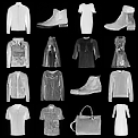

In [8]:
preview_files = sorted(SAMPLE_DIR.glob("sample_epoch_*.png")) if SAMPLE_DIR.exists() else []
if preview_files:
    latest_preview = preview_files[-1]
    print("Preview mới nhất:", latest_preview.name)
    display(Image(filename=str(latest_preview)))
else:
    print("Chưa tìm thấy ảnh preview trong:", SAMPLE_DIR)


## 5. Sinh thêm ảnh từ checkpoint (tùy chọn)

Sampling DDPM 1000 timestep có thể mất thời gian. Mặc định cell này **không chạy** để tránh vô tình tạo thêm một lượt sampling dài. Đổi `RUN_EXTRA_SAMPLING = True` nếu cần sinh thêm ảnh.

In [9]:
RUN_EXTRA_SAMPLING = False  # Chỉ đổi thành True khi thực sự muốn sinh thêm ảnh.
N_EXTRA_SAMPLES = 16

if RUN_EXTRA_SAMPLING:
    from src.models import DDPM
    from src.training.train_ddpm import EMA
    from src.utils import get_device, save_image_grid

    device = get_device()
    model_config = checkpoint["model_config"]
    model = DDPM(**model_config).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])

    ema_state = checkpoint.get("ema_state_dict")
    if ema_state is not None:
        ema = EMA(model, decay=ema_state.get("decay", 0.999))
        ema.load_state_dict(ema_state)
        ema.copy_to(model)

    model.eval()
    with torch.inference_mode():
        generated = model.sample(n=N_EXTRA_SAMPLES, device=device)

    generated_path = SAMPLE_DIR / "sample_from_04_ddpm_notebook.png"
    save_image_grid(generated, generated_path, nrow=4)
    print("Đã lưu:", generated_path)
    display(Image(filename=str(generated_path)))
else:
    print("Bỏ qua sampling bổ sung. Notebook chỉ đọc kết quả đã có.")


Bỏ qua sampling bổ sung. Notebook chỉ đọc kết quả đã có.


## 6. Kết luận và thông tin bàn giao

Sau khi chạy notebook, ghi lại các thông tin thực tế:

- Dataset và kích thước ảnh lấy từ config/checkpoint.
- Số epochs đã hoàn thành.
- Train loss và validation loss cuối cùng.
- Best validation loss.
- Thời gian training.
- Đường dẫn checkpoint best/last.
- Đường dẫn loss curve và ảnh preview.

Không dùng riêng MSE loss để kết luận chất lượng ảnh sinh; cần quan sát ảnh và dùng FID/đánh giá đa dạng ở giai đoạn đánh giá chung.